# How much can we compress the pose, and how much error should we tolerate?

The proposal asks for "the smallest representation size that keeps decoding accuracy within a set tolerance".
That needs two things this notebook tries to pin down with numbers:

1. **Do we reproduce Santello et al. (1998)?** ("2 PCs explain > 80 % of 15 joint angles"). If not, why not?
2. **The dimension ladder**: anatomical degrees of freedom → recorded angles → linear/intrinsic dimension of the
   data → what an EMG decoder can actually *see*.
3. **Compression curves in the benchmark's own metrics** (angle MAE in °, landmark distance in mm), for movements
   seen and unseen by the PCA.
4. **Which pose dimensions does the pretrained EMG model actually decode?** (per-PC R² on a held-out user)
5. **A free bottleneck experiment**: project the pretrained model's predictions onto k PCs, no retraining.
6. **Tolerance**: three ways to set it, and a recommended rule.

Data: mini dataset (1 held-out user, 15 stages, both hands). Pretrained checkpoints from Meta.
Everything here is "this person": the numbers must be redone on the full dataset, but the *method* carries over.

## Setup

**Locally:** run `uv sync --extra cpu` in the repo root and pick the **semg2pose** kernel. The cell below does nothing.

**On Colab:** select *Runtime → Change runtime type → Runtime version 2026.07* (Python 3.12), optionally with a T4 GPU.
Run the cell below once; when it says so, do *Runtime → Restart session* and run the notebook from the top again.

In [1]:
# Colab only: clone semg2pose (with the emg2pose submodule) and install it. Locally this does nothing.
import os
import subprocess
import sys
from pathlib import Path

if "google.colab" in sys.modules:
    if not (3, 10) <= sys.version_info[:2] < (3, 13):
        raise RuntimeError("Select Runtime > Change runtime type > Runtime version 2026.07 "
                           "(Python 3.12), then run this cell again.")
    REPO_DIR = Path("/content/semg2pose")
    if not REPO_DIR.exists():
        subprocess.run(["git", "clone", "--recurse-submodules",
                        "https://github.com/eljoserass/semg2pose.git", str(REPO_DIR)], check=True)
    try:
        import semg2pose  # noqa: F401  (installed in a previous run + restart)
        print("semg2pose is installed, continue.")
    except ImportError:
        subprocess.run(["bash", str(REPO_DIR / "scripts" / "colab_setup.sh")], check=True,
                       env={**os.environ, "PYTHON": sys.executable})
        print("Installed. Now: Runtime > Restart session, then run the notebook from the top.")
else:
    print("Local kernel:", sys.executable)

Local kernel: /home/rodri/projects/emg2poseneuromatch/semg2pose/.venv/bin/python


In [2]:
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from scipy import signal

from emg2pose.kinematics import forward_kinematics, load_default_hand_model
from emg2pose.constants import LANDMARKS, NO_MOVEMENT_LANDMARKS
from semg2pose.data import FS, JOINT_NAMES, download_mini_dataset, list_sessions, load_session
from semg2pose.model import download_checkpoints, load_pretrained, predict_session

warnings.filterwarnings("ignore")
DATASET_DIR = download_mini_dataset()
CKPT_DIR = download_checkpoints()
torch.set_num_threads(4)
plt.rcParams["figure.dpi"] = 100
STEP = 40          # 2 kHz -> 50 Hz
FS_LOW = FS // STEP

Dataset already downloaded: /home/rodri/emg2pose_dataset_mini
Checkpoints already downloaded: /home/rodri/emg2pose_model_checkpoints


## 1. Load the poses (50 Hz, valid frames, both hands)

In [3]:
sessions = list_sessions(DATASET_DIR)
frames = []
for sid, row in sessions.iterrows():
    _, angles, ok, meta = load_session(row.path)
    a, ok = angles[::STEP], ok[::STEP]
    vel = signal.savgol_filter(a, 11, 2, deriv=1, delta=1 / FS_LOW, axis=0)
    good = ~np.convolve(~ok, np.ones(7), mode="same").astype(bool)  # drop 60 ms around tracking failures
    speed = np.linalg.norm(vel, axis=1)
    frames.append(pd.DataFrame({"session": sid, "stage": row.stage, "side": row.side,
                                "t": np.arange(len(a))[good] / FS_LOW, "speed": speed[good]})
                  .join(pd.DataFrame(a[good], columns=JOINT_NAMES)))
frames = pd.concat(frames, ignore_index=True)
X = frames[JOINT_NAMES].values
print(f"{len(frames)} frames = {len(frames) / FS_LOW / 60:.1f} min, {frames.stage.nunique()} stages, both hands")

83689 frames = 27.9 min, 15 stages, both hands


## 2. Do we reproduce Santello et al. (1998)?

**What they did.** 5 subjects *imagined grasping* 57 familiar objects (an egg, a hammer, a CD...) and held the
final hand shape. A CyberGlove measured **15 angles**: MCP and PIP flexion of the four fingers (8), abduction
*between* adjacent fingers (3), and four thumb angles (rotation, abduction, MCP, IP). PCA per subject:
**PC1 + PC2 > 80 %** of the variance.

**How our data differ.** (i) continuous *movements* instead of *held* final postures; (ii) 20 angles, including the
DIP joints and per-finger abduction; (iii) the emg2pose stages were designed to **individuate** fingers (counting,
pointing, pinches, abduction series, hand signs), not to grasp objects.

**Plan.** Make our data step by step more "Santello-like" and watch PC1 + PC2:

- **15 Santello-like angles**: 4 × MCP_FE, 4 × PIP_FE, 3 *relative* abductions (index−middle, middle−ring,
  ring−pinky MCP_AA), thumb CMC_FE, CMC_AA, MCP_FE, IP_FE.
- **Held postures**: frames where the hand is still (joint speed below 0.5 rad/s for at least 0.3 s); each hold
  is collapsed to its mean posture, so every held hand shape counts once, like Santello's 57 grasps.
- **Whole-hand stages**: as a contrast, all frames of the stages dominated by whole-hand opening/closing
  (closest thing to grasping in emg2pose; there are no real objects).

In [4]:
F = {n: frames[n].values for n in JOINT_NAMES}
santello = np.column_stack(
    [F[f"{f}_MCP_FE"] for f in ["INDEX", "MIDDLE", "RING", "PINKY"]]
    + [F[f"{f}_PIP_FE"] for f in ["INDEX", "MIDDLE", "RING", "PINKY"]]
    + [F["INDEX_MCP_AA"] - F["MIDDLE_MCP_AA"], F["MIDDLE_MCP_AA"] - F["RING_MCP_AA"], F["RING_MCP_AA"] - F["PINKY_MCP_AA"]]
    + [F["THUMB_CMC_FE"], F["THUMB_CMC_AA"], F["THUMB_MCP_FE"], F["THUMB_IP_FE"]])
assert santello.shape[1] == 15

# Held postures: runs of still frames (speed < 0.5 rad/s) lasting >= 0.3 s, collapsed to their mean
still = frames.speed.values < 0.5
run_id = np.cumsum(np.r_[True, (np.diff(still.astype(int)) != 0) | (np.diff(frames.session.values) != 0)
                         | (np.diff(frames.t.values) > 1.5 / FS_LOW)])
holds = pd.DataFrame({"run": run_id, "still": still, "stage": frames.stage.values})
holds = holds[holds.still]
lengths = holds.groupby("run").size()
keep_runs = lengths.index[lengths >= int(0.3 * FS_LOW)]
in_hold = np.isin(run_id, keep_runs) & still
hold_of = run_id[in_hold]
hold_stage = frames.stage.values[in_hold]


def collapse(Z):
    df = pd.DataFrame(Z[in_hold]).assign(run=hold_of)
    return df.groupby("run").mean().values


hold_stages = pd.Series(hold_stage, index=hold_of).groupby(level=0).first().values
print(f"{len(keep_runs)} held postures found (median duration "
      f"{lengths.loc[keep_runs].median() / FS_LOW:.1f} s)")


def pca_stats(Z):
    Zc = Z - Z.mean(0)
    ev = np.linalg.svd(Zc, compute_uv=False) ** 2
    ev = ev / ev.sum()
    cum = np.cumsum(ev)
    return {"PC1 %": 100 * ev[0], "PC1+2 %": 100 * cum[1],
            "PCs for 80 %": int(np.searchsorted(cum, 0.8) + 1), "PCs for 90 %": int(np.searchsorted(cum, 0.9) + 1),
            "n": len(Z)}, cum


GRASP_STAGES = ["HandClawGraspFlicks", "ThumbsSwipesWholeHand", "WristFlexionAbduction"]
g = np.isin(frames.stage.values, GRASP_STAGES)
variants = {
    "A. all frames, 20 angles": X,
    "B. all frames, 15 Santello-like angles": santello,
    "C. held postures, 20 angles": collapse(X),
    "D. held postures, 15 Santello-like angles": collapse(santello),
    "E. all frames, 15 angles, whole-hand stages only": santello[g],
}
rows, curves = {}, {}
for name, Z in variants.items():
    rows[name], curves[name] = pca_stats(np.degrees(Z))
santello_table = pd.DataFrame(rows).T
santello_table.loc["Santello et al. 1998 (5 subjects, 57 imagined grasps)"] = [np.nan, 80.0, 2, np.nan, 57]
santello_table.round(1)

55 held postures found (median duration 0.5 s)


,PC1 %,PC1+2 %,PCs for 80 %,PCs for 90 %,n
"A. all frames, 20 angles",53.1,65.5,5.0,8.0,83689.0
"B. all frames, 15 Santello-like angles",56.2,69.0,4.0,6.0,83689.0
"C. held postures, 20 angles",66.7,75.6,3.0,5.0,55.0
"D. held postures, 15 Santello-like angles",68.7,80.5,2.0,5.0,55.0
"E. all frames, 15 angles, whole-hand stages only",73.2,86.5,2.0,3.0,15228.0
"Santello et al. 1998 (5 subjects, 57 imagined grasps)",NaN,80.0,2.0,NaN,57.0


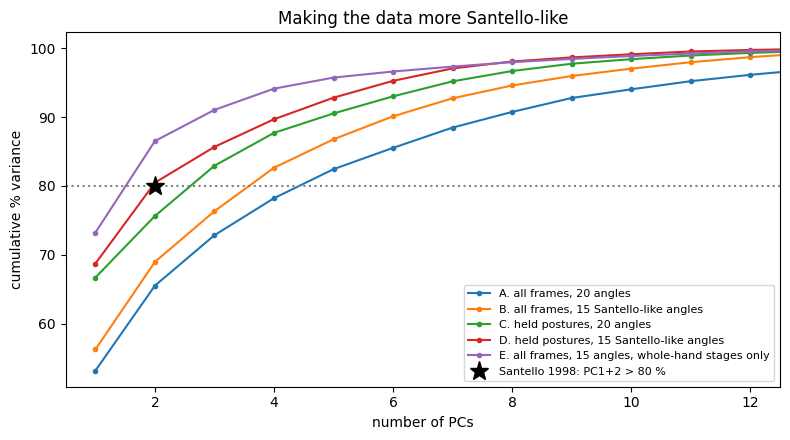

In [5]:
fig, ax = plt.subplots(figsize=(8, 4.5))
for name, cum in curves.items():
    ax.plot(range(1, len(cum) + 1), 100 * cum, "o-", ms=3, label=name)
ax.axhline(80, color="gray", ls=":")
ax.plot([2], [80], "k*", ms=14, label="Santello 1998: PC1+2 > 80 %")
ax.set_xlabel("number of PCs"); ax.set_ylabel("cumulative % variance"); ax.set_xlim(0.5, 12.5)
ax.legend(fontsize=8); ax.set_title("Making the data more Santello-like")
plt.tight_layout(); plt.show()

**Per stage.** The same question task by task (all frames, 20 angles): synergy dominance depends a lot on the
movement repertoire.

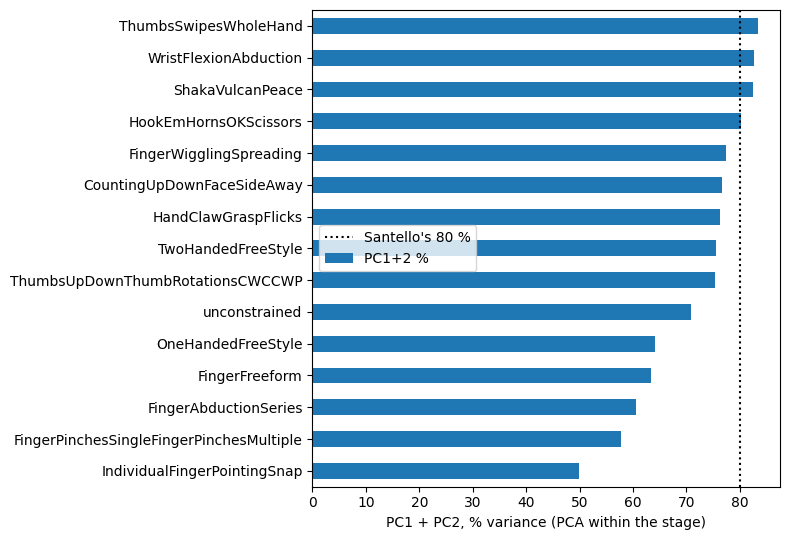

In [6]:
per_stage = pd.DataFrame({st: pca_stats(np.degrees(X[frames.stage.values == st]))[0]
                          for st in sorted(frames.stage.unique())}).T.sort_values("PC1+2 %")
ax = per_stage["PC1+2 %"].plot.barh(figsize=(8, 5.5), color="tab:blue")
ax.axvline(80, color="k", ls=":", label="Santello's 80 %")
ax.set_xlabel("PC1 + PC2, % variance (PCA within the stage)"); ax.legend()
plt.tight_layout(); plt.show()

**What we see** (numbers in the table above):

- With all frames and 20 angles, PC1 + PC2 ≈ 65 %, well below 80 %. Using Santello's 15 angles adds a little;
  using **held postures** adds a lot. With **both** (variant D: ~55 held hand shapes, about as many as his 57
  grasps, 15 angles), **PC1 + PC2 ≈ 80 %: we reproduce Santello's number** under his conditions.
- The difference between A and D is the lesson. "How many dimensions does the hand have?" depends on *what is
  measured* (held end-postures vs whole movements; with or without DIP/abduction) and *which movements* are
  included. The transitions between postures and the individuated movements add dimensions.
- Why the full dataset is higher-dimensional: Santello's task (grasping objects) *is* the synergy. Grasps
  are dominated by "close the whole hand around something of a certain size". emg2pose deliberately adds
  individuated movements (count with your fingers, point, pinch with each finger, spread fingers, hand signs),
  which live in the higher PCs. Later studies of natural, daily hand use and of manipulation (e.g. Todorov &
  Ghahramani 2004; Ingram et al. 2008) also needed more components than 2 to reach high variance.
- Whole-hand stages (E) pass the 80 % line even with all frames, and so do several single stages below; the
  finger-by-finger stages need many more PCs.
  **The intrinsic dimension of "the hand" depends on what the hand is asked to do.** For the project: the
  compression curve must be measured on the full stage set, and per stage.

## 3. The dimension ladder: anatomy → recordings → data → what EMG can see

| level | number | where it comes from |
|---|---|---|
| anatomical DOF of the hand (incl. wrist) | ~27 | 4 per finger × 4 + 5 thumb + 6 wrist/forearm (classic count) |
| DOF in the UmeTrack hand model | 22 | 20 finger angles + 2 wrist angles |
| **recorded target** | **20** | finger and thumb angles (wrist not labelled) |
| Santello's measured set | 15 | glove sensors (no DIP; DIP is mechanically coupled to PIP) |
| PCs for 95 % / 90 % of variance | computed below | linear redundancy |
| intrinsic dimension (TwoNN, coarse scale) | ~8-9 | `joint_space_manifold.ipynb` section 6 |
| participation ratio | computed below | "effective" number of dims, dominated by the big PCs |
| PCs the pretrained EMG model decodes with R² > 0.1 | computed in section 5 | what the *EMG* can see |

In [7]:
Xc = X - X.mean(0)
_, s_all, Vt_all = np.linalg.svd(Xc, full_matrices=False)
ev_all = s_all ** 2 / (s_all ** 2).sum()
cum_all = np.cumsum(ev_all)
PR = (s_all ** 2).sum() ** 2 / ((s_all ** 2) ** 2).sum()
n90, n95 = [int(np.searchsorted(cum_all, p) + 1) for p in (0.90, 0.95)]
print(f"PCs for 95 %: {n95}, for 90 %: {n90}; participation ratio: {PR:.1f}")

PCs for 95 %: 11, for 90 %: 8; participation ratio: 3.2


## 4. Compression curves in the benchmark's metrics

PCA reconstruction error of the **ground truth** (no EMG involved): this is the *floor* any decoder that goes
through a k-dimensional PCA bottleneck must pay. Two ways of fitting the PCA:

- **seen movements**: PCA fitted on all of this user's data (optimistic; with 158 training users the PCA would see
  all 23 training stages from many hands, so held-out-*user* evaluation is close to this case);
- **unseen movements**: leave-one-stage-out (PCA fitted without the stage being reconstructed; the
  held-out-*stage* case).

Metrics as in the benchmark: angle MAE (°) and landmark distance (mm, forward kinematics of the default hand).

In [8]:
hand_model = load_default_hand_model()
LM_IDX = [lm.index for lm in LANDMARKS if lm.name not in NO_MOVEMENT_LANDMARKS]


def fk(A):
    with torch.no_grad():
        return forward_kinematics(torch.tensor(A.T[None], dtype=torch.float32), hand_model)[0].numpy()


def landmark_mm(A, B, every=5):
    return float(np.linalg.norm(fk(A[::every])[:, LM_IDX] - fk(B[::every])[:, LM_IDX], axis=-1).mean())


def project(Z, mu, Vt, k):
    W = Vt[:k]
    return (Z - mu) @ W.T @ W + mu


KS = [1, 2, 3, 4, 5, 6, 8, 10, 12, 16, 20]
stages = sorted(frames.stage.unique())
st_arr = frames.stage.values
mu_all = X.mean(0)
loso_fits = {}
for st in stages:
    tr = X[st_arr != st]
    m = tr.mean(0)
    loso_fits[st] = (m, np.linalg.svd(tr - m, full_matrices=False)[2])

rows = []
for k in KS:
    seen = project(X, mu_all, Vt_all, k)
    unseen = np.empty_like(X)
    for st in stages:
        sel = st_arr == st
        unseen[sel] = project(X[sel], *loso_fits[st], k)
    rows.append({"k": k,
                 "seen: MAE (°)": np.degrees(np.abs(seen - X).mean()),
                 "unseen: MAE (°)": np.degrees(np.abs(unseen - X).mean()),
                 "seen: landmark (mm)": landmark_mm(seen, X, 10),
                 "unseen: landmark (mm)": landmark_mm(unseen, X, 10)})
floor = pd.DataFrame(rows).set_index("k")
floor.round(2).T

k,1,2,3,4,5,6,8,10,12,16,20
seen: MAE (°),12.44,10.23,9.28,8.38,7.57,6.81,5.35,4.16,3.31,1.44,0.0
unseen: MAE (°),12.89,10.87,10.03,9.24,8.51,7.94,6.47,4.84,3.88,1.87,0.0
seen: landmark (mm),16.47,13.73,11.55,10.80,9.92,9.11,7.10,5.43,4.27,2.59,0.0
unseen: landmark (mm),17.12,14.79,12.59,11.94,11.35,10.77,8.62,6.51,4.97,3.16,0.0


## 5. Which pose dimensions does the pretrained EMG model decode?

We run Meta's pretrained vemg2pose (tracking and regression, see `pipeline_overview.ipynb`) on every recording
of this **held-out user**, then express both prediction and ground truth in the PCA basis of the ground truth
and compute **R² per PC**: how much of the variance of each pose direction the model recovers.
(`unconstrained` is left out: the hand barely moves, so it says nothing about decoding.)

Lightning automatically upgraded your loaded checkpoint from v1.8.6 to v2.2.2. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../emg2pose_model_checkpoints/tracking_vemg2pose.ckpt`


Lightning automatically upgraded your loaded checkpoint from v1.8.6 to v2.2.2. To apply the upgrade to your files permanently, run `python -m pytorch_lightning.utilities.upgrade_checkpoint ../../../../emg2pose_model_checkpoints/regression_vemg2pose.ckpt`


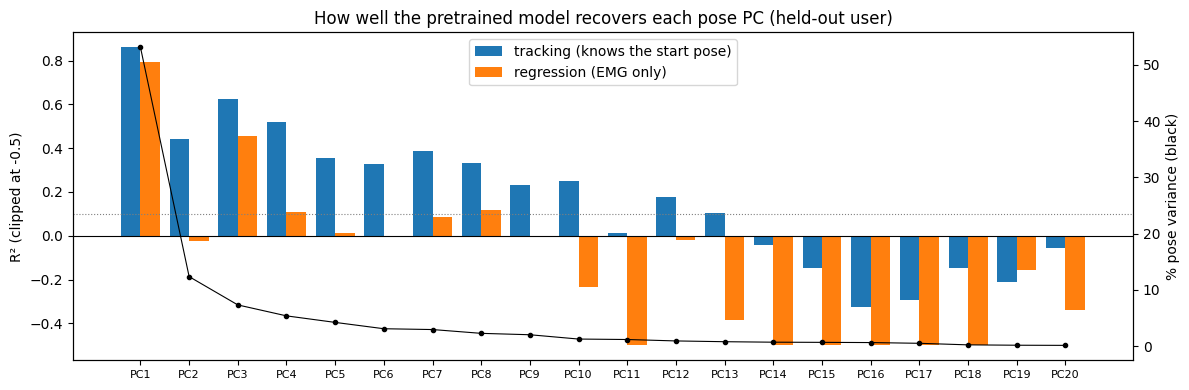

PCs decoded with R² > 0.1: {'tracking': 12, 'regression': 4}


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8,PC9,PC10,PC11,PC12,PC13,PC14,PC15,PC16,PC17,PC18,PC19,PC20
tracking,0.86,0.44,0.63,0.52,0.35,0.33,0.39,0.33,0.23,0.25,0.01,0.18,0.11,-0.04,-0.15,-0.33,-0.29,-0.15,-0.21,-0.05
regression,0.79,-0.02,0.45,0.11,0.01,-0.00,0.09,0.12,-0.01,-0.23,-0.82,-0.02,-0.39,-1.00,-0.56,-1.18,-0.93,-0.83,-0.16,-0.34
% pose variance,53.15,12.36,7.33,5.38,4.22,3.10,2.95,2.28,2.03,1.26,1.18,0.93,0.79,0.70,0.67,0.64,0.51,0.23,0.16,0.14


In [9]:
preds = {}
for exp in ["tracking_vemg2pose", "regression_vemg2pose"]:
    module = load_pretrained(exp, CKPT_DIR)
    for _, row in sessions.iterrows():
        P, Y = predict_session(module, row.path)
        if P is not None:
            preds[(exp, row.stage, row.side)] = (P, Y)


def stack(exp, drop=("unconstrained",)):
    keys = [k for k in preds if k[0] == exp and k[1] not in drop]
    return (np.vstack([preds[k][0] for k in keys]), np.vstack([preds[k][1] for k in keys]),
            np.concatenate([np.full(len(preds[k][1]), k[1]) for k in keys]))


r2_pc = {}
for exp in ["tracking_vemg2pose", "regression_vemg2pose"]:
    P, Y, _ = stack(exp)
    zp, zy = (P - mu_all) @ Vt_all.T, (Y - mu_all) @ Vt_all.T
    r2_pc[exp.split("_")[0]] = 1 - ((zp - zy) ** 2).sum(0) / ((zy - zy.mean(0)) ** 2).sum(0)
r2_pc = pd.DataFrame(r2_pc, index=[f"PC{i + 1}" for i in range(20)])
r2_pc["% pose variance"] = 100 * ev_all

fig, ax = plt.subplots(figsize=(12, 4))
xx = np.arange(20)
ax.bar(xx - 0.2, r2_pc.tracking.clip(lower=-0.5), 0.4, label="tracking (knows the start pose)")
ax.bar(xx + 0.2, r2_pc.regression.clip(lower=-0.5), 0.4, label="regression (EMG only)")
ax.axhline(0, color="k", lw=0.8); ax.axhline(0.1, color="gray", ls=":", lw=0.8)
ax.set_xticks(xx, r2_pc.index, fontsize=8); ax.set_ylabel("R² (clipped at -0.5)")
ax2 = ax.twinx(); ax2.plot(xx, r2_pc["% pose variance"], "k.-", lw=0.8); ax2.set_ylabel("% pose variance (black)")
ax.legend(loc="upper center"); ax.set_title("How well the pretrained model recovers each pose PC (held-out user)")
plt.tight_layout(); plt.show()
n_seen = {m: int((r2_pc[m] > 0.1).sum()) for m in ["tracking", "regression"]}
print("PCs decoded with R² > 0.1:", n_seen)
r2_pc.round(2).T

**Reading it.** This is the most important plot of the notebook.

- **Regression (EMG only)** recovers PC1 (open/close) well (R² ≈ 0.8), one more of the big directions partly
  (R² ≈ 0.4; whether it shows up as PC2 or PC3 depends on the exact PCA basis, since those two have similar
  variance), a couple more weakly (R² ≈ 0.1), and **nothing beyond ~PC10**: R² is negative there. Negative R²
  means its predictions in those directions *add* error: predicting the mean would be better.
- **Tracking** recovers more directions (~12 with R² > 0.1), largely because it starts from the true pose and
  only has to follow changes; beyond ~PC13 it is negative too.
- So the pose needs 8-11 dimensions to describe (section 3), but **what today's EMG model actually delivers
  on a new person is a lower-dimensional signal**, dramatically so without the start pose. That is the strongest argument for the project: a
  bottleneck at k ≈ 4-10 should cost little, and could even help by removing directions where the model only
  adds noise.

## 6. A free bottleneck experiment: project the predictions onto k PCs

Without retraining anything: take the model's 20-D prediction, keep only its first k PCA coordinates
(PCA fitted on the ground truth, leave-one-stage-out so the PCA never saw the stage), map back to 20 angles,
and score. Three curves:

- **full**: the model as is (flat line);
- **projected prediction**: what a (post-hoc) k-D bottleneck would give;
- **floor**: projected ground truth, the unavoidable compression error.

If "projected" is close to "full" at small k, the tail of the prediction carried little useful information.
(A model *trained* with the bottleneck could do better than this post-hoc version, or worse; that is Stage 2.)

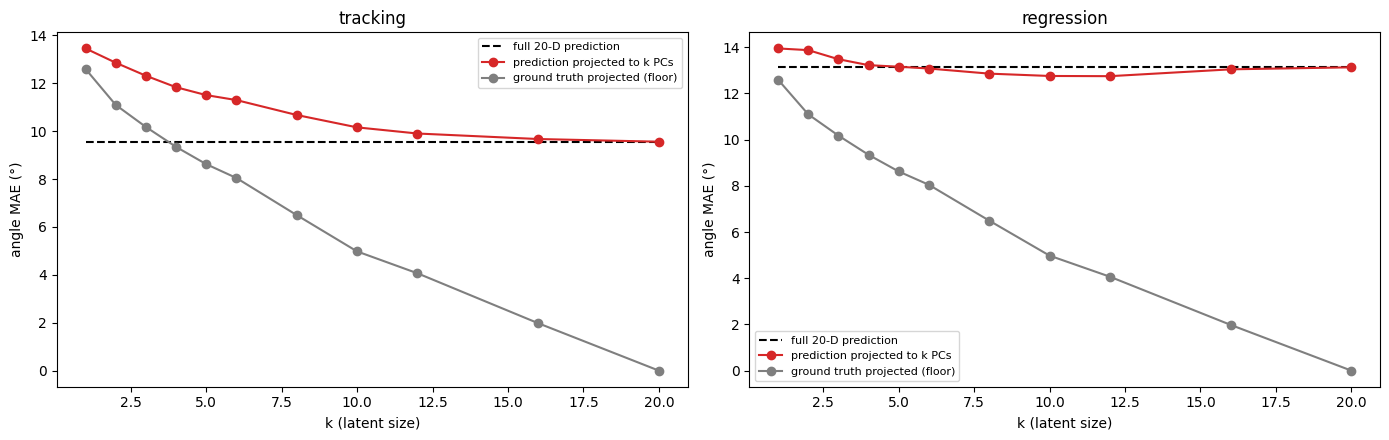

projected prediction (°)            full (°)           floor (°)  \
model               regression tracking regression tracking regression   
k                                                                        
1                        13.95    13.46      13.13     9.56      12.60   
2                        13.88    12.86      13.13     9.56      11.10   
3                        13.48    12.32      13.13     9.56      10.18   
4                        13.23    11.84      13.13     9.56       9.34   
5                        13.16    11.51      13.13     9.56       8.62   
6                        13.08    11.30      13.13     9.56       8.04   
8                        12.86    10.68      13.13     9.56       6.49   
10                       12.76    10.16      13.13     9.56       4.98   
12                       12.75     9.90      13.13     9.56       4.07   
16                       13.05     9.67      13.13     9.56       1.98   
20                       13.13     9.56      13.13     9.56       0.00   

                
model tracking  
k               
1        12.60  
2        11.10  
3        10.18  
4         9.34  
5         8.62  
6         8.04  
8         6.49  
10        4.98  
12        4.07  
16        1.98  
20        0.00

In [10]:
proj_rows = []
for exp in ["tracking_vemg2pose", "regression_vemg2pose"]:
    P, Y, st_lab = stack(exp)
    for k in KS:
        Pk, Yk = np.empty_like(P), np.empty_like(Y)
        for st in np.unique(st_lab):
            sel = st_lab == st
            Pk[sel] = project(P[sel], *loso_fits[st], k)
            Yk[sel] = project(Y[sel], *loso_fits[st], k)
        proj_rows.append({"model": exp.split("_")[0], "k": k,
                          "full (°)": np.degrees(np.abs(P - Y).mean()),
                          "projected prediction (°)": np.degrees(np.abs(Pk - Y).mean()),
                          "floor (°)": np.degrees(np.abs(Yk - Y).mean()),
                          "full (mm)": landmark_mm(P, Y), "projected prediction (mm)": landmark_mm(Pk, Y),
                          "floor (mm)": landmark_mm(Yk, Y)})
proj = pd.DataFrame(proj_rows)

fig, axs = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, model in zip(axs, ["tracking", "regression"]):
    d = proj[proj.model == model].set_index("k")
    ax.plot(d.index, d["full (°)"], "k--", label="full 20-D prediction")
    ax.plot(d.index, d["projected prediction (°)"], "o-", color="tab:red", label="prediction projected to k PCs")
    ax.plot(d.index, d["floor (°)"], "o-", color="tab:gray", label="ground truth projected (floor)")
    ax.set_xlabel("k (latent size)"); ax.set_ylabel("angle MAE (°)"); ax.set_title(f"{model}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()
proj.pivot(index="k", columns="model", values=["projected prediction (°)", "full (°)", "floor (°)"]).round(2)

**Reading it.**

- **Regression**: projecting to k ≈ 6-10 PCs gives **the same or slightly lower error** than the full
  prediction. A post-hoc bottleneck already *denoises*.
- **Tracking**: the error rises slowly as k drops: about +0.3° at k = 12, +1.1° at k = 8, +2.3° at k = 4.
- Errors do **not** add like independent errors. If they did, total ≈ √(full² + floor²); the observed
  projected error is clearly smaller, because the model's own errors are concentrated in the same tail
  directions that the bottleneck removes.

## 7. Tolerance: how much are we willing to lose?

There is no universal answer; there are three defensible ways to set it, and the proposal should pick one
**before** running Stage 2 (pre-registration):

**(a) Relative to the baseline.** "k is acceptable if its error is at most δ % above the direct model". Simple,
common in compression papers. δ = 5 % ≈ 0.5° for tracking, ≈ 0.65° for regression on this user.

**(b) Relative to noise you cannot beat.** Differences smaller than the run-to-run variability of training
(different random seeds) or than the noise in the labels are not meaningful. Seed variability needs ≥ 3 training
runs of the baseline (Stage 2, month 4). A **lower bound** on label noise can be read from the data: the
high-frequency jitter of the motion-capture angles (real finger movement has almost no power above ~15 Hz):

In [11]:
jitter = []
for _, row in sessions.iterrows():
    _, angles, ok, _ = load_session(row.path)
    sos = signal.butter(4, 15, btype="highpass", fs=FS, output="sos")
    hf = signal.sosfiltfilt(sos, angles, axis=0)
    good = ~np.convolve(~ok, np.ones(401), mode="same").astype(bool)  # far from IK failures (filter edges)
    jitter.append(np.abs(hf[good]).mean(0))
jitter_deg = np.degrees(np.mean(jitter, axis=0))
print(f"High-frequency (>15 Hz) jitter of the labels: mean {jitter_deg.mean():.2f}° per joint "
      f"(max {jitter_deg.max():.2f}°, {JOINT_NAMES[int(jitter_deg.argmax())]})")

High-frequency (>15 Hz) jitter of the labels: mean 0.10° per joint (max 0.15°, MIDDLE_PIP_FE)


This is only the *random* part of the label noise. Systematic errors (marker placement, fitting a generic hand
model to each person) are likely larger and cannot be measured from the data alone. So label noise does not set
a useful tolerance here; seed variability (to be measured) will.

**(c) A statistical non-inferiority test.** The cleanest formulation for a paper: pick a margin δ, then test, *paired
across held-out users* (the full dataset has 20 test users per condition), whether
`error(k) − error(direct) < δ` with a one-sided confidence interval. The smallest k that passes is the answer.
This combines (a) for the margin with a proper accounting of the variability across people.

**What the numbers here suggest** (post-hoc projection, one user, so only indicative):

In [12]:
def smallest_k(model, delta_rel):
    d = proj[proj.model == model].set_index("k")
    ok = d.index[d["projected prediction (°)"] <= d["full (°)"] * (1 + delta_rel)]
    return int(ok.min()) if len(ok) else None


tol = pd.DataFrame({model: {f"δ = {int(100 * dl)} %": smallest_k(model, dl) for dl in [0.0, 0.02, 0.05, 0.10, 0.20]}
                    for model in ["tracking", "regression"]})
tol.index.name = "smallest k with projected error ≤ (1 + δ) × full"
tol

,tracking,regression
smallest k with projected error ≤ (1 + δ) × full,,
δ = 0 %,20,6
δ = 2 %,16,4
δ = 5 %,12,3
δ = 10 %,10,1
δ = 20 %,6,1


## 8. Which joints pay for the compression?

Per-joint MAE of the floor (ground truth projected, unseen-stage PCA) at a few k, next to the per-joint error of
the pretrained tracking model.

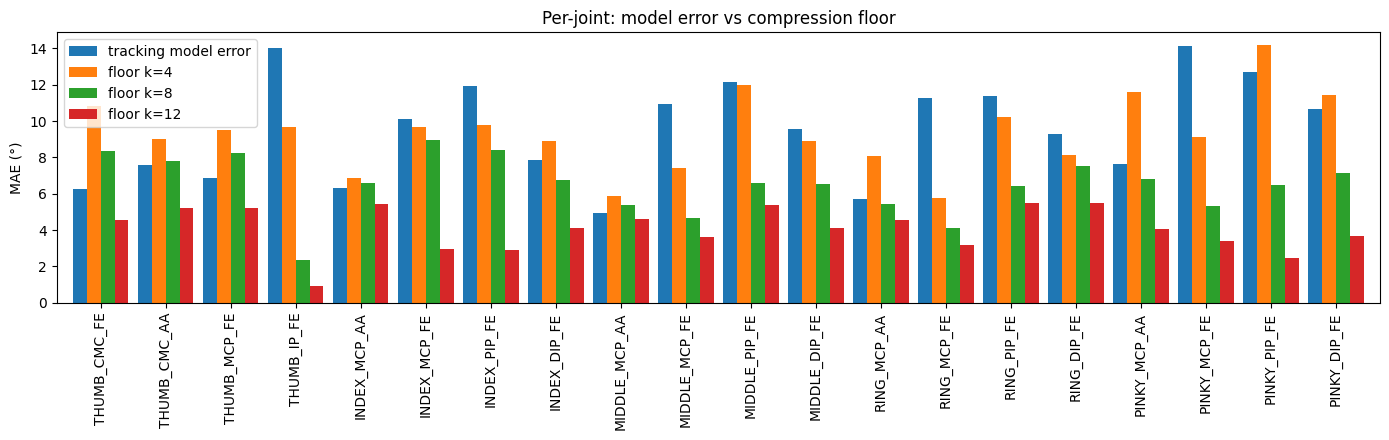

In [13]:
P, Y, st_lab = stack("tracking_vemg2pose")
per_joint = {"tracking model error": np.degrees(np.abs(P - Y).mean(0))}
for k in [4, 8, 12]:
    Yk = np.empty_like(Y)
    for st in np.unique(st_lab):
        sel = st_lab == st
        Yk[sel] = project(Y[sel], *loso_fits[st], k)
    per_joint[f"floor k={k}"] = np.degrees(np.abs(Yk - Y).mean(0))
per_joint = pd.DataFrame(per_joint, index=JOINT_NAMES)
ax = per_joint.plot.bar(figsize=(14, 4.5), width=0.85)
ax.set_ylabel("MAE (°)"); ax.set_title("Per-joint: model error vs compression floor")
plt.tight_layout(); plt.show()

## 9. Conclusions

In [14]:
print(f"Santello replication: PC1+2 = {santello_table.iloc[0]['PC1+2 %']:.0f} % (all frames, 20 angles) -> "
      f"{santello_table.iloc[3]['PC1+2 %']:.0f} % (held postures, 15 Santello-like angles); Santello: > 80 %")
print(f"Pose dimension: {n90} PCs for 90 %, {n95} for 95 %, participation ratio {PR:.1f}")
print(f"PCs decoded by the pretrained model with R² > 0.1: tracking {n_seen['tracking']}, regression {n_seen['regression']}")
for k in [4, 8, 12]:
    print(f"k={k:2d}: floor seen {floor.loc[k, 'seen: MAE (°)']:.1f}° / unseen {floor.loc[k, 'unseen: MAE (°)']:.1f}°;  "
          + "  ".join(f"{m}: projected {proj[(proj.model == m) & (proj.k == k)]['projected prediction (°)'].item():.2f}° "
                      f"vs full {proj[(proj.model == m) & (proj.k == k)]['full (°)'].item():.2f}°"
                      for m in ["tracking", "regression"]))

Santello replication: PC1+2 = 66 % (all frames, 20 angles) -> 80 % (held postures, 15 Santello-like angles); Santello: > 80 %
Pose dimension: 8 PCs for 90 %, 11 for 95 %, participation ratio 3.2
PCs decoded by the pretrained model with R² > 0.1: tracking 12, regression 4
k= 4: floor seen 8.4° / unseen 9.2°;  tracking: projected 11.84° vs full 9.56°  regression: projected 13.23° vs full 13.13°
k= 8: floor seen 5.4° / unseen 6.5°;  tracking: projected 10.68° vs full 9.56°  regression: projected 12.86° vs full 13.13°
k=12: floor seen 3.3° / unseen 3.9°;  tracking: projected 9.90° vs full 9.56°  regression: projected 12.75° vs full 13.13°


1. **Santello, reproduced under his conditions.** Held postures + his 15 angles give PC1 + PC2 ≈ 80 %. The full
   data (all frames, 20 angles, all stages) give ≈ 65 %: emg2pose includes movements *between* postures and
   individuated finger movements, so it is genuinely higher-dimensional than grasping.
2. **There is something to reduce, but less than Santello suggests**: ~8 PCs for 90 % of the variance of the pose.
   The more interesting gap is between the **pose dimension (~8-11)** and the **dimension the EMG model can decode
   on a new person** (regression: 1 PC well, ~4 with R² > 0.1; tracking: ~12 with R² > 0.1).
3. **A post-hoc bottleneck already costs little** (tracking) **or nothing** (regression) at k ≈ 6-10, which makes
   the Stage 2 hypothesis plausible and suggests the candidate sizes to carry forward: **k ∈ {4, 6, 8, 12}**.
4. **Tolerance**: pick a relative margin δ in advance (e.g. 5 %), measure seed-to-seed variability of the direct
   baseline, and use a paired non-inferiority test across held-out users. Report the floor (compression error of
   the ground truth) next to every decoding result, in both ° and mm.
5. **Caveat**: one user. The PCA should be fitted on training users only and evaluated on held-out users and
   stages of the full dataset.